League of Legends: What Drives Winning?

Project Overview
This project analyzes professional League of Legends matches from 2026 using data from Oracle's Elixir. The goal is to understand how early-game gold advantages and dragon objectives relate to a team's chances of winning.
Using Python, Pandas, and Matplotlib, I explore how gold differences at 15 minutes, first dragon control, and total dragons secured relate to match outcomes.

Questions
How much does having a gold lead at 15 minutes affect win rate?
How does the size of a gold lead relate to winning?
How important is securing the first dragon?
Can first dragon control help teams win even when behind in gold?

In [1]:
import pandas as pd

df = pd.read_csv(
    "data/2026_LoL_esports_match_data_from_OraclesElixir.csv",
    low_memory=False
)

df.shape
df.head()
df.info()
df["position"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117432 entries, 0 to 117431
Columns: 165 entries, gameid to opp_deathsat25
dtypes: float64(124), int64(18), object(23)
memory usage: 147.8+ MB


position
top     19572
jng     19572
mid     19572
bot     19572
sup     19572
team    19572
Name: count, dtype: int64

Gold Advantage at 15 Minutes

The first part of this analysis looks at how a team's gold difference at 15 minutes relates to its chances of winning.
Gold is important in League of Legends because it allows players to purchase items and become stronger. I want to see whether teams with an early gold advantage are more likely to win and how much the size of that advantage matters.

In [2]:
teams = df[df["position"] == "team"].copy()
teams.shape

teams[["gameid", "teamname", "result", "golddiffat15"]].head(10)
teams.groupby(teams["golddiffat15"] > 0)["result"].mean()

teams["golddiffat15"].isna().sum()
teams["golddiffat15"].notna().sum()

teams_clean = teams.dropna(subset=["golddiffat15"]).copy()
teams_clean.groupby(
    teams_clean["golddiffat15"] > 0
)["result"].mean()

golddiffat15
False    0.254863
True     0.745188
Name: result, dtype: float64

Findings: Early Gold Advantage

The results show that teams with a gold advantage at 15 minutes are more likely to win than teams that are behind or tied.
This suggests that building an early gold lead is strongly associated with winning professional League of Legends matches. However, being ahead does not guarantee victory.

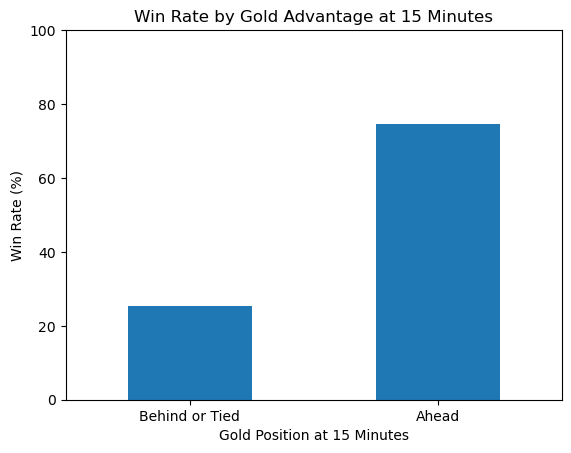

In [3]:
import matplotlib.pyplot as plt

win_rates = teams_clean.groupby(
    teams_clean["golddiffat15"] > 0
)["result"].mean() * 100

win_rates.index = ["Behind or Tied", "Ahead"]

win_rates.plot(kind="bar")

plt.title("Win Rate by Gold Advantage at 15 Minutes")
plt.xlabel("Gold Position at 15 Minutes")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

How the Size of a Gold Lead Affects Win Rate

This analysis divides teams into six categories based on their gold difference at 15 minutes.
Instead of simply comparing teams that are ahead or behind, I want to see how different sizes of gold advantages or deficits relate to winning.
This helps determine whether larger early-game gold leads are associated with higher win rates.

In [4]:
bins = [-float("inf"), -3000, -1000, 0, 1000, 3000, float("inf")]
labels = [
    "Below -3000",
    "-3000 to -1000",
    "-1000 to 0",
    "0 to 1000",
    "1000 to 3000",
    "Above 3000"
]
teams_clean["gold_category"] = pd.cut(
    teams_clean["golddiffat15"],
    bins=bins,
    labels=labels
)
teams_clean.groupby(
    "gold_category", observed=True
)["result"].agg(["mean", "count"])

,mean,count
gold_category,,
Below -3000,0.076005,2934
-3000 to -1000,0.263864,3949
-1000 to 0,0.434066,2730
0 to 1000,0.565934,2730
1000 to 3000,0.736069,3948
Above 3000,0.924310,2933


Findings: Size of Gold Advantage

The results show that win rate increases as a team's gold advantage at 15 minutes grows.
Teams with a gold lead of 3,000 or more had a win rate of approximately 92.4%.
This suggests that larger early-game gold leads are strongly associated with winning, while teams with large gold deficits have a much harder time coming back.

Dragon Control and Win Rate

This section examines how securing dragons relates to winning professional League of Legends matches.
I first compare the win rates of teams that secured the first dragon against those that did not. Then, I analyze how the total number of dragons secured relates to a team's chances of winning.
The goal is to understand whether dragon control is associated with winning matches.

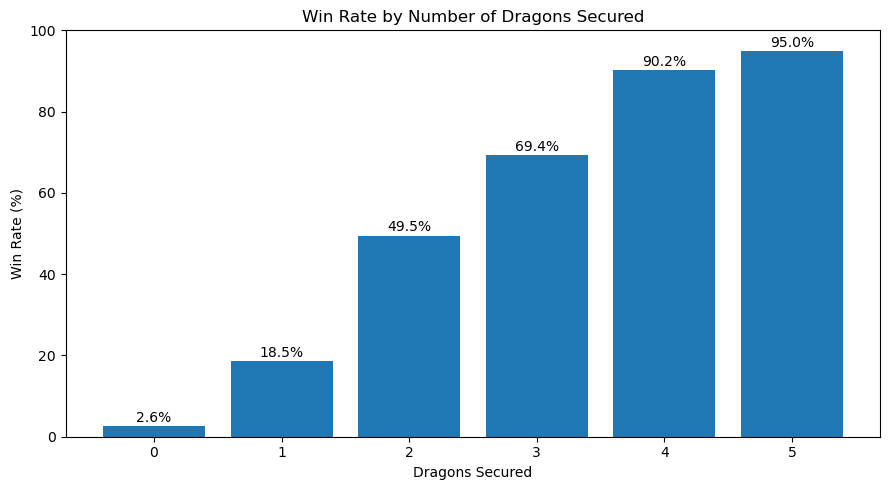

In [5]:
[col for col in teams_clean.columns if "dragon" in col.lower()]
teams_clean.groupby("firstdragon")["result"].agg(
    ["mean", "count"]
)
teams_clean.groupby(
    "dragons", observed=True
)["result"].agg(["mean", "count"])
dragon_winrate = teams_clean.groupby("dragons")["result"].mean()
dragon_winrate = (
    teams_clean[teams_clean["dragons"] <= 5]
    .groupby("dragons")["result"]
    .mean() * 100
)
plt.figure(figsize=(9, 5))
bars = plt.bar(dragon_winrate.index.astype(int), dragon_winrate.values)
plt.title("Win Rate by Number of Dragons Secured")
plt.xlabel("Dragons Secured")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 100)
plt.xticks(range(6))
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1,
             f"{height:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Findings: Dragon Control

The results show that teams securing the first dragon won approximately 61.7% of their matches.
The analysis also shows that teams securing more dragons generally had higher win rates.
This suggests that dragon control is strongly associated with winning professional League of Legends matches. However, securing dragons does not guarantee victory.

First Dragon vs. Gold Advantage

This analysis examines how first dragon control and gold advantage at 15 minutes relate to winning.
I divide teams into two groups: those ahead in gold and those behind or even. Within each group, I compare win rates based on whether the team secured the first dragon.
The goal is to see whether securing the first dragon is associated with a higher win rate, even when a team is behind in gold.

                                mean  count
gold_status    firstdragon                 
Ahead          0.0          0.661110   3839
               1.0          0.801109   5772
Behind or Even 0.0          0.198616   5780
               1.0          0.339682   3833


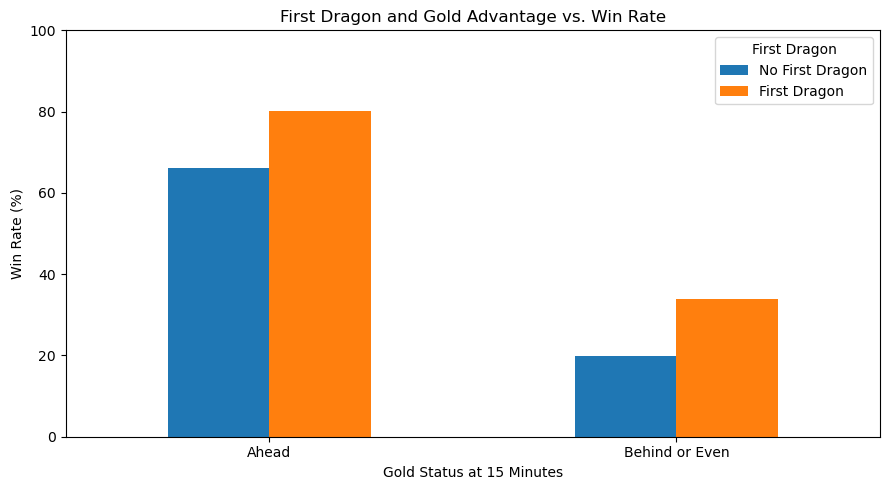

In [6]:
teams_clean["gold_status"] = teams_clean["golddiffat15"].apply(
    lambda x: "Ahead" if x > 0 else "Behind or Even"
)
comparison = teams_clean.groupby(
    ["gold_status", "firstdragon"]
)["result"].agg(["mean", "count"])
print(comparison)
comparison_plot = (
    teams_clean.groupby(["gold_status", "firstdragon"])["result"]
    .mean()
    .unstack() * 100
)
comparison_plot.columns = ["No First Dragon", "First Dragon"]
comparison_plot.plot(kind="bar", figsize=(9, 5))
plt.title("First Dragon and Gold Advantage vs. Win Rate")
plt.xlabel("Gold Status at 15 Minutes")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="First Dragon")
plt.tight_layout()
plt.show()

Findings: First Dragon vs. Gold Advantage

The results show that securing the first dragon is associated with higher win rates, regardless of gold advantage at 15 minutes.
Teams ahead in gold with first dragon won 80.1% of matches, compared to 66.1% without it.
Teams behind or even in gold with first dragon won 34.0% of matches, compared to 19.9% without it.

This suggests that securing the first dragon is associated with better chances of winning, even when a team is behind in gold.
However, having a gold advantage remains a stronger indicator of winning.

Dragon Soul Analysis: Limitations and Future Research

I originally wanted to investigate which dragon soul type was associated with the highest win rate in professional League of Legends.
The dataset contains information about individual dragon types, including Infernal, Mountain, Ocean, Cloud, Chemtech, and Hextech. However, it does not explicitly identify which dragon soul was obtained during each match.
Although dragon counts provide clues about the soul type, I could not reliably classify every match using the available information.
Future Research: With additional match data or a more reliable method of identifying dragon souls, this analysis could be expanded to compare win rates across all six soul types.

In [7]:
dragon_columns = [
    col for col in teams_clean.columns
    if "dragon" in col.lower() or "soul" in col.lower()
]
print(dragon_columns)
teams_clean[dragon_columns].head(10)
[col for col in df.columns
 if "dragon" in col.lower() or "soul" in col.lower()]
print(df.columns.tolist())
dragon_types = [
    "infernals", "mountains", "clouds",
    "oceans", "chemtechs", "hextechs"
]

df.loc[
    (df["position"] == "team") &
    (df["dragons"] >= 4),
    ["gameid", "result", "dragons"] + dragon_types
].head(10)

soul_teams = df[
    (df["position"] == "team") &
    (df["dragons"] >= 4)
].copy()

(soul_teams[dragon_types] >= 3).sum()

['firstdragon', 'dragons', 'opp_dragons', 'dragons (type unknown)']
['gameid', 'datacompleteness', 'url', 'league', 'year', 'split', 'playoffs', 'date', 'game', 'patch', 'participantid', 'side', 'position', 'playername', 'playerid', 'teamname', 'teamid', 'firstPick', 'champion', 'ban1', 'ban2', 'ban3', 'ban4', 'ban5', 'pick1', 'pick2', 'pick3', 'pick4', 'pick5', 'gamelength', 'result', 'kills', 'deaths', 'assists', 'teamkills', 'teamdeaths', 'doublekills', 'triplekills', 'quadrakills', 'pentakills', 'firstblood', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'team kpm', 'ckpm', 'firstdragon', 'dragons', 'opp_dragons', 'elementaldrakes', 'opp_elementaldrakes', 'infernals', 'mountains', 'clouds', 'oceans', 'chemtechs', 'hextechs', 'dragons (type unknown)', 'elders', 'opp_elders', 'firstherald', 'heralds', 'opp_heralds', 'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons', 'atakhans', 'opp_atakhans', 'firsttower', 'towers', 'opp_towers', 'firstmidtower', 'firs

infernals    214
mountains    201
clouds       208
oceans       190
chemtechs    212
hextechs     180
dtype: int64

Elder Dragon and Win Rate

This analysis examines the relationship between securing Elder Dragon and winning professional League of Legends matches.
I want to compare the win rates of teams that secured Elder Dragon against teams that did not.
The goal is to determine how strongly Elder Dragon control is associated with winning a match.

elders
NaN    98192
0.0    18456
1.0      741
2.0       40
3.0        2
4.0        1
Name: count, dtype: int64
elders
0.0    18456
1.0      741
NaN      332
2.0       40
3.0        2
4.0        1
Name: count, dtype: int64
           win_rate  matches
got_elder                   
False         48.57    18456
True          83.67      784


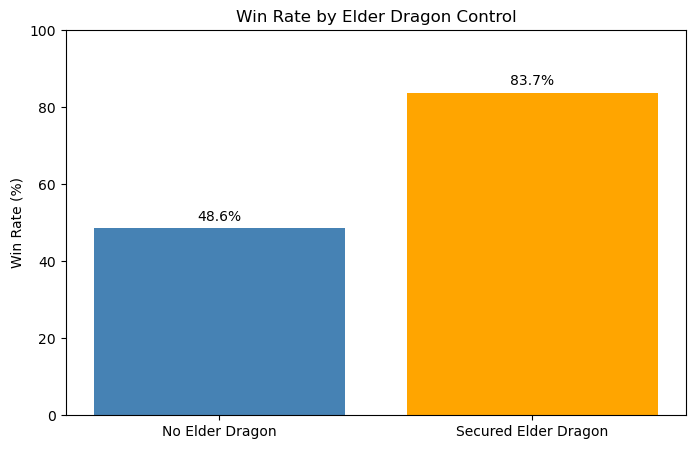

In [8]:
print(df["elders"].value_counts(dropna=False))

elder_teams = df[df["position"] == "team"].copy()
print(elder_teams["elders"].value_counts(dropna=False))

elder_clean = elder_teams.dropna(subset=["elders", "result"]).copy()
elder_clean["got_elder"] = elder_clean["elders"] > 0
elder_winrates = elder_clean.groupby("got_elder").agg(
    win_rate=("result", "mean"),
    matches=("result", "size")
)
elder_winrates["win_rate"] *= 100
print(elder_winrates.round(2))

plt.figure(figsize=(8, 5))
plt.bar(
    ["No Elder Dragon", "Secured Elder Dragon"],
    elder_winrates["win_rate"],
    color=["steelblue", "orange"]
)
plt.ylabel("Win Rate (%)")
plt.title("Win Rate by Elder Dragon Control")
plt.ylim(0, 100)
for i, rate in enumerate(elder_winrates["win_rate"]):
    plt.text(i, rate + 2, f"{rate:.1f}%", ha="center")
plt.show()

Findings: Elder Dragon Control

Teams that secured at least one Elder Dragon won 83.67% of their matches, compared to 48.57% for teams that did not.
This represents a 35.1 percentage-point difference, suggesting a strong relationship between Elder Dragon control and winning.
However, Elder Dragon appears late in matches, and teams that secure it may already have an advantage. These results demonstrate correlation rather than proving that Elder Dragon directly causes teams to win.

Gold Advantage vs. Elder Dragon

This analysis examines how securing Elder Dragon relates to winning when teams have different gold advantages at 15 minutes.
I want to compare win rates for teams that were ahead or behind in gold, based on whether they secured Elder Dragon.
The goal is to investigate whether Elder Dragon control is associated with successful comebacks for teams that were initially behind.

['elders', 'opp_elders', 'totalgold', 'earnedgold', 'earnedgoldshare', 'goldspent', 'goldat10', 'opp_goldat10', 'golddiffat10', 'goldat15', 'opp_goldat15', 'golddiffat15', 'goldat20', 'opp_goldat20', 'golddiffat20', 'goldat25', 'opp_goldat25', 'golddiffat25', 'got_elder']
                          win_rate  matches
gold_status    got_elder                   
Ahead          False         73.73     9141
               True          90.34      466
Behind or Even False         23.82     9292
               True          73.82      317


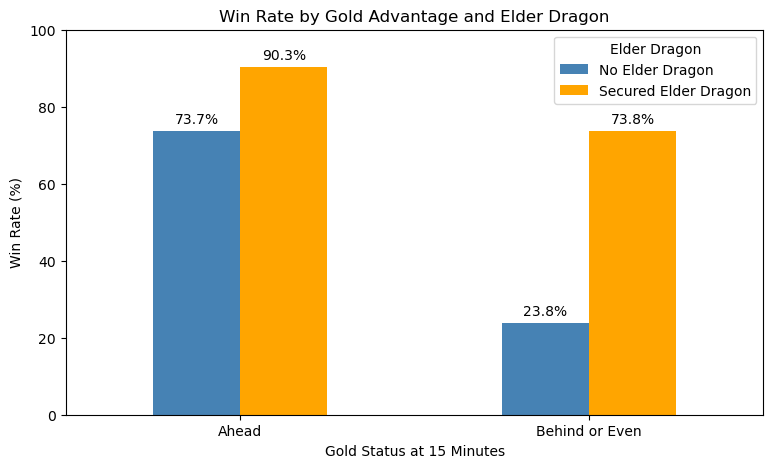

In [11]:
print([
    col for col in elder_clean.columns
    if "gold" in col.lower() or "elder" in col.lower()
])
elder_gold = elder_clean.dropna(subset=["golddiffat15"]).copy()
elder_gold["gold_status"] = elder_gold["golddiffat15"].apply(
    lambda x: "Ahead" if x > 0 else "Behind or Even"
)
elder_gold_winrates = elder_gold.groupby(
    ["gold_status", "got_elder"]
).agg(
    win_rate=("result", "mean"),
    matches=("result", "size")
)
elder_gold_winrates["win_rate"] *= 100

print(elder_gold_winrates.round(2))

elder_plot = elder_gold_winrates["win_rate"].unstack()
elder_plot.columns = ["No Elder Dragon", "Secured Elder Dragon"]
ax = elder_plot.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange"],
    rot=0
)
plt.title("Win Rate by Gold Advantage and Elder Dragon")
plt.xlabel("Gold Status at 15 Minutes")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 100)
plt.legend(title="Elder Dragon")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
plt.show()

Findings: Gold Advantage vs. Elder Dragon

Teams ahead in gold at 15 minutes won 90.3% of their matches when they secured Elder Dragon, compared to 73.7% without it.
More notably, teams that were behind or even in gold at 15 minutes won 73.8% of their matches when they secured Elder Dragon, compared to just 23.8% without it.
This suggests that Elder Dragon control is strongly associated with winning, even for teams that were initially behind.
However, Elder Dragon is a late-game objective, meaning teams may have already recovered from their early deficits before securing it. These findings demonstrate correlation rather than causation.

Comeback Analysis: Overcoming Large Gold Deficits

This analysis examines how often professional League of Legends teams recover from significant gold deficits at 15 minutes.
I want to investigate the win rates of teams trailing by 3,000 or more gold and compare them with teams facing smaller deficits.
The goal is to understand how difficult it is to overcome an early disadvantage and whether larger gold deficits make successful comebacks less likely.

                  win_rate  matches
deficit_group                      
3000+ Behind          7.60     2934
2000-2999 Behind     20.14     1693
1000-1999 Behind     31.07     2256
0-999 Behind         43.41     2730


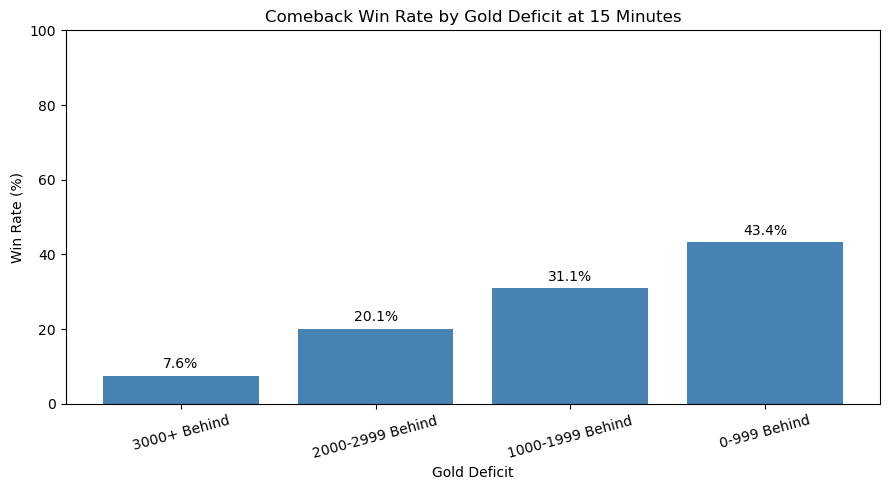

In [14]:
comeback_data = teams_clean.dropna(
    subset=["golddiffat15", "result"]
).copy()
comeback_data["deficit_group"] = pd.cut(
    comeback_data["golddiffat15"],
    bins=[-float("inf"), -3000, -2000, -1000, 0],
    labels=["3000+ Behind", "2000-2999 Behind",
            "1000-1999 Behind", "0-999 Behind"]
)
comeback_winrates = comeback_data.groupby(
    "deficit_group", observed=True
).agg(
    win_rate=("result", "mean"),
    matches=("result", "size")
)
comeback_winrates["win_rate"] *= 100

print(comeback_winrates.round(2))

plt.figure(figsize=(9, 5))
bars = plt.bar(
    comeback_winrates.index,
    comeback_winrates["win_rate"],
    color="steelblue"
)
plt.title("Comeback Win Rate by Gold Deficit at 15 Minutes")
plt.xlabel("Gold Deficit")
plt.ylabel("Win Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.show()


Findings: Comeback Analysis

Teams trailing by 3,000 or more gold at 15 minutes won only 7.6% of their matches, demonstrating how difficult it is to overcome a large early deficit.
Teams trailing by 2,000–2,999 gold had a 20.1% win rate, while teams trailing by 1,000–1,999 gold won 31.1% of their matches.
Teams with smaller deficits of less than 1,000 gold had the highest comeback win rate at 43.4%.
These findings show a clear relationship between the size of an early gold deficit and the likelihood of winning. As the deficit increases, successful comebacks become significantly less common.